# Homework 7

**Coverage:** Lectures 21–22: Gaussian-process priors and conditioning.

**Due:** Sunday, November 1, 2026, at 11:59 p.m. Eastern Time.

**Total:** 100 points.

## Instructions

- All downloading, fitting, prediction, and plotting code is provided. Run the code cells in order without changing their contents; enter your responses in the answer text cells. You are not expected to study the implementation or write code.
- Answer the six lettered parts. Show the requested algebra in Problem 1; short paragraphs or bullet points are sufficient for the interpretation questions. No separate report is required.
- Submit a PDF of your completed notebook, including your name, answers, generated tables, and generated figures.
- This notebook uses NumPy, SciPy, pandas, and Matplotlib, available in a standard CPU Google Colab runtime. It normally downloads one small official NIST data file, so internet access is required when you first run it. It does not need package installation, Google Drive, or an absolute file path. If NIST is temporarily unavailable and the teaching team provides the official file, upload it to the Colab Files panel as `Chwirut1.dat` and rerun the cell.
- The NIST source does not document physical units for these two columns. Accordingly, report them as **NIST-reported response units** and **NIST-reported distance units**.

Relevant reading: [Gaussian-process priors](https://predictivesciencelab.github.io/data-analytics-se/lecture21/reading-21.html), [Gaussian-process conditioning](https://predictivesciencelab.github.io/data-analytics-se/lecture22/reading-22.html), and the Lecture 22 material on standardized-error diagnostics.

## Student details

**First name:**Harishteja

**Last name:**Peddi

**Purdue email:**peddih@purdue.edu


## Problem 1: Basic Gaussian-process mathematics (20 points)

**Credit:** Course exercise based on the finite-dimensional definition and covariance construction in [Lecture 21](https://predictivesciencelab.github.io/data-analytics-se/lecture21/reading-21.html).

### (a) Mean and covariance of function values (10 points)

Let

$$
f(\cdot)\sim\operatorname{GP}\!\left(m_f(\cdot),k_f(\cdot,\cdot)\right).
$$

For arbitrary inputs $\mathbf{x}_{1:n}=(\mathbf{x}_1,\ldots,\mathbf{x}_n)$, define

$$
\mathbf{f}_{1:n}
=
\left(f(\mathbf{x}_1),\ldots,f(\mathbf{x}_n)\right)^\top.
$$

State the finite-dimensional distribution of $\mathbf{f}_{1:n}$. Then use that distribution, together with coordinate vectors, to show that for every $i,j$,

$$
\mathbb{E}\!\left[f(\mathbf{x}_i)\right]=m_f(\mathbf{x}_i),
\qquad
\mathbb{C}\!\left[f(\mathbf{x}_i),f(\mathbf{x}_j)\right]
=k_f(\mathbf{x}_i,\mathbf{x}_j).
$$

Your argument should make clear how the entries of the Gaussian mean vector and covariance matrix produce these scalar identities.


*Your answer:*

By the finite-dimensional definition of a Gaussian process,

$$
\mathbf f_{1:n}\sim\mathcal N(\mathbf m,\mathbf K),
$$

where

$$
\mathbf m=
\begin{pmatrix}
m_f(x_1)\\
\vdots\\
m_f(x_n)
\end{pmatrix},
\qquad
\mathbf K=\left[k_f(x_i,x_j)\right]_{i,j=1}^{n}.
$$

Therefore,

$$
\mathbb E[\mathbf f_{1:n}]=\mathbf m,
\qquad
\operatorname{Cov}(\mathbf f_{1:n})=\mathbf K.
$$

Let $\mathbf e_i\in\mathbb R^n$ be the $i$-th coordinate vector, whose $i$-th entry is $1$ and all other entries are $0$. Then

$$
f(x_i)=\mathbf e_i^\top\mathbf f_{1:n}.
$$

Using linearity of expectation,

$$
\begin{aligned}
\mathbb E[f(x_i)]
&=\mathbb E[\mathbf e_i^\top\mathbf f_{1:n}]\\
&=\mathbf e_i^\top\mathbb E[\mathbf f_{1:n}]\\
&=\mathbf e_i^\top\mathbf m\\
&=\boxed{m_f(x_i)}.
\end{aligned}
$$

Thus, the mean of $f(x_i)$ is the $i$-th entry of the Gaussian mean vector.

Using the definition of covariance,

$$
\begin{aligned}
\mathbb C[f(x_i),f(x_j)]
&=\mathbb E\left[
(f(x_i)-m_f(x_i))(f(x_j)-m_f(x_j))
\right]\\
&=\mathbb E\left[
\mathbf e_i^\top(\mathbf f_{1:n}-\mathbf m)
(\mathbf f_{1:n}-\mathbf m)^\top\mathbf e_j
\right]\\
&=\mathbf e_i^\top
\mathbb E\left[
(\mathbf f_{1:n}-\mathbf m)
(\mathbf f_{1:n}-\mathbf m)^\top
\right]\mathbf e_j\\
&=\mathbf e_i^\top\mathbf K\mathbf e_j\\
&=K_{ij}\\
&=\boxed{k_f(x_i,x_j)}.
\end{aligned}
$$

Here, $\mathbf e_i^\top\mathbf K\mathbf e_j$ selects the entry in row $i$ and column $j$ of the covariance matrix. Hence, for every $i,j$,

$$
\boxed{
\mathbb E[f(x_i)]=m_f(x_i),
\qquad
\mathbb C[f(x_i),f(x_j)]=k_f(x_i,x_j).
}
$$

### (b) Adding Gaussian processes (10 points)

Suppose

$$
g(\cdot)\sim\operatorname{GP}\!\left(m_g(\cdot),k_g(\cdot,\cdot)\right)
$$

is independent of $f(\cdot)$. For constants $a,b\in\mathbb{R}$ and a deterministic function $r(\cdot)$, define

$$
h(\mathbf{x})=r(\mathbf{x})+a f(\mathbf{x})+b g(\mathbf{x}).
$$

Using an arbitrary finite collection of inputs, show that $h(\cdot)$ is a Gaussian process and identify its mean and covariance functions. State precisely where independence is used. Then specialize your answer to $a=b=1$, $r=0$, $m_f=m_g=0$,

$$
k_f(x,x')=\sigma_L^2xx',
\qquad
k_g(x,x')=\sigma_S^2\exp\!\left[-\frac{(x-x')^2}{2\ell^2}\right],
$$

and briefly interpret the two contributions to the covariance of $h$.


*Your answer:*

Choose any finite collection of inputs $x_1,\ldots,x_n$ and define

$$
\mathbf f=
\begin{pmatrix}
f(x_1)\\ \vdots\\ f(x_n)
\end{pmatrix},
\qquad
\mathbf g=
\begin{pmatrix}
g(x_1)\\ \vdots\\ g(x_n)
\end{pmatrix},
\qquad
\mathbf r=
\begin{pmatrix}
r(x_1)\\ \vdots\\ r(x_n)
\end{pmatrix}.
$$

By the Gaussian-process definitions,

$$
\mathbf f\sim\mathcal N(\mathbf m_f,\mathbf K_f),
\qquad
\mathbf g\sim\mathcal N(\mathbf m_g,\mathbf K_g),
$$

where $(\mathbf m_f)_i=m_f(x_i)$, $(\mathbf K_f)_{ij}=k_f(x_i,x_j)$, and similarly for $g$.

Independence of the two processes implies that $\mathbf f$ and $\mathbf g$ are independent Gaussian vectors. Consequently, their stacked vector is jointly Gaussian with block-diagonal covariance:

$$
\begin{pmatrix}
\mathbf f\\
\mathbf g
\end{pmatrix}
\sim
\mathcal N\left(
\begin{pmatrix}
\mathbf m_f\\
\mathbf m_g
\end{pmatrix},
\begin{pmatrix}
\mathbf K_f & \mathbf 0\\
\mathbf 0 & \mathbf K_g
\end{pmatrix}
\right).
$$

The vector of values of $h$ is the affine transformation

$$
\mathbf h
=
\mathbf r+a\mathbf f+b\mathbf g
=
\mathbf r+
\begin{pmatrix}
a\mathbf I_n & b\mathbf I_n
\end{pmatrix}
\begin{pmatrix}
\mathbf f\\
\mathbf g
\end{pmatrix}.
$$

An affine transformation of a jointly Gaussian vector is Gaussian. Therefore,

$$
\boxed{
\mathbf h\sim
\mathcal N\left(
\mathbf r+a\mathbf m_f+b\mathbf m_g,\,
a^2\mathbf K_f+b^2\mathbf K_g
\right).
}
$$

Because this holds for every finite collection of inputs, $h(\cdot)$ is a Gaussian process:

$$
\boxed{
h(\cdot)\sim\operatorname{GP}
\left(m_h(\cdot),k_h(\cdot,\cdot)\right),
}
$$

with mean function

$$
\boxed{
m_h(x)=r(x)+a\,m_f(x)+b\,m_g(x)
}
$$

and covariance function

$$
\boxed{
k_h(x,x')=a^2k_f(x,x')+b^2k_g(x,x').
}
$$

Precisely, independence is used to establish joint Gaussianity of the stacked vector and to make the cross-covariance blocks zero. In scalar form,

$$
\begin{aligned}
\operatorname{Cov}(h(x),h(x'))
&=a^2k_f(x,x')+b^2k_g(x,x')\\
&\quad+ab\,\operatorname{Cov}(f(x),g(x'))\\
&\quad+ab\,\operatorname{Cov}(g(x),f(x')).
\end{aligned}
$$

Independence makes both cross-covariance terms zero. The deterministic function $r$ changes only the mean and contributes no covariance.

For $a=b=1$, $r=0$, and $m_f=m_g=0$, we obtain

$$
\boxed{
h(\cdot)\sim\operatorname{GP}\left(
0,\,
\sigma_L^2xx'
+\sigma_S^2\exp\left[-\frac{(x-x')^2}{2\ell^2}\right]
\right).
}
$$

The two covariance contributions have the following interpretations:

- **Linear contribution:** $\sigma_L^2xx'$ describes a random linear trend through the origin. It corresponds to $f(x)=Wx$, where $W\sim\mathcal N(0,\sigma_L^2)$, so $\sigma_L^2$ controls the variance of the slope.
- **Squared-exponential contribution:** $\sigma_S^2\exp[-(x-x')^2/(2\ell^2)]$ describes smooth fluctuations around that trend. The parameter $\sigma_S^2$ controls their pointwise variance, while $\ell>0$ controls their correlation length: nearby inputs are strongly correlated, and larger $\ell$ gives more slowly varying fluctuations.

Thus, $h$ combines an independent random linear trend with smooth fluctuations.

## Problem 2: Learning from replicated calibration data and checking the fit (80 points)

**Credit:** Data come directly from the U.S. National Institute of Standards and Technology (NIST), [Chwirut1 nonlinear-regression test data](https://www.itl.nist.gov/div898/strd/nls/data/chwirut1.shtml), accessed October 23, 2026. NIST describes an ultrasonic response measured at different metal distances. This assignment uses those observations for a Gaussian-process exercise; the split, models, diagnostics, and questions were constructed for this course. The code downloads the [official data file](https://www.itl.nist.gov/div898/strd/nls/data/LINKS/DATA/Chwirut1.dat) and checks its SHA-256 digest before using it.

The data contain replicated responses at the same distance settings. We hold out all observations at distances $2.25$, $2.50$, and $2.75$ to test **interpolation**. We also hold out all observations at distances at least $5.00$ to test **extrapolation**. All other observations form the training set. The response is standardized using the training observations only; reported predictions and metrics are converted back to NIST-reported response units.

Run the supplied cell. The left panel shows the split. The right panel shows the response standard deviation among replicates at each distance; it is a descriptive summary, not a fitted noise model.


Data source used: official NIST URL
Verified NIST file: d9a055dfe5af71a8754c00f073ef00f8fed2e3fd1c6fd20cea8fd62d7cc3ed84
Training response mean = 36.2951; SD = 24.4449


,Split,Observations,Distance levels,Minimum distance,Maximum distance
0,Training,159,15,0.50,4.75
1,Interpolation,26,3,2.25,2.75
2,Extrapolation,29,4,5.00,6.00


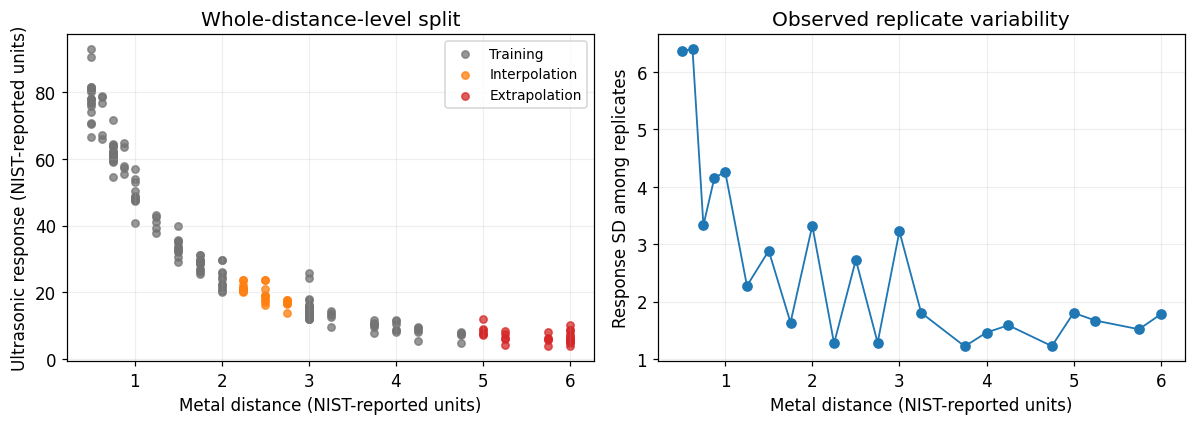

,Distance,Replicates,Mean response,Replicate SD
0,3.750,7,10.093,1.224
1,0.625,5,73.580,6.394


In [5]:
import hashlib
import io
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize
from scipy.stats import chi2, probplot

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})

DATA_URL = "https://www.itl.nist.gov/div898/strd/nls/data/LINKS/DATA/Chwirut1.dat"
EXPECTED_SHA256 = "d9a055dfe5af71a8754c00f073ef00f8fed2e3fd1c6fd20cea8fd62d7cc3ed84"
request = Request(DATA_URL, headers={"User-Agent": "ME539 educational notebook"})
local_data_path = Path("Chwirut1.dat")
if local_data_path.exists():
    raw = local_data_path.read_bytes()
    data_origin = "uploaded local Chwirut1.dat"
else:
    raw = urlopen(request, timeout=30).read()
    data_origin = "official NIST URL"
observed_digest = hashlib.sha256(raw).hexdigest()
if observed_digest != EXPECTED_SHA256:
    raise RuntimeError("The downloaded NIST file did not match the expected SHA-256 digest.")

values = np.loadtxt(io.StringIO(raw.decode("ascii")), skiprows=60)
response = values[:, 0]
distance = values[:, 1]

interpolation_levels = np.array([2.25, 2.50, 2.75])
interpolation_mask = np.isin(distance, interpolation_levels)
extrapolation_mask = distance >= 5.0
training_mask = ~(interpolation_mask | extrapolation_mask)
split_masks = {
    "Training": training_mask,
    "Interpolation": interpolation_mask,
    "Extrapolation": extrapolation_mask,
}

training_mean = response[training_mask].mean()
training_sd = response[training_mask].std(ddof=1)
standardized_response = (response - training_mean) / training_sd

audit_rows = []
for split_name, mask in split_masks.items():
    audit_rows.append({
        "Split": split_name,
        "Observations": int(mask.sum()),
        "Distance levels": int(np.unique(distance[mask]).size),
        "Minimum distance": distance[mask].min(),
        "Maximum distance": distance[mask].max(),
    })
split_audit = pd.DataFrame(audit_rows)

level_summary = (
    pd.DataFrame({"Distance": distance, "Response": response})
    .groupby("Distance")["Response"]
    .agg(["count", "mean", "std"])
    .reset_index()
    .rename(columns={"count": "Replicates", "mean": "Mean response", "std": "Replicate SD"})
)

print(f"Data source used: {data_origin}")
print(f"Verified NIST file: {observed_digest}")
print(f"Training response mean = {training_mean:.4f}; SD = {training_sd:.4f}")
display(split_audit)

colors = {"Training": "0.45", "Interpolation": "tab:orange", "Extrapolation": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for split_name, mask in split_masks.items():
    axes[0].scatter(distance[mask], response[mask], s=23, alpha=0.75,
                    color=colors[split_name], label=split_name)
axes[0].set(xlabel="Metal distance (NIST-reported units)",
            ylabel="Ultrasonic response (NIST-reported units)",
            title="Whole-distance-level split")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.2)

axes[1].plot(level_summary["Distance"], level_summary["Replicate SD"], "o-", lw=1.2)
axes[1].set(xlabel="Metal distance (NIST-reported units)",
            ylabel="Response SD among replicates",
            title="Observed replicate variability")
axes[1].grid(alpha=0.2)
fig.tight_layout()
plt.show()

replicate_extremes = pd.concat([
    level_summary.nsmallest(1, "Replicate SD"),
    level_summary.nlargest(1, "Replicate SD"),
], ignore_index=True)
display(replicate_extremes.round(3))


### (a) Audit the experiment (10 points)

Report the total number of observations and distance levels, then report the observation and distance-level counts in each split. Why do we withhold entire distance levels instead of randomly withholding individual observations? Why is the response standardized using the training set only?


*Your answer:*


The dataset contains **214 observations at 22 distinct distance levels**. The split is:

| Split | Number of observations | Number of distance levels |
|---|---:|---:|
| Training | 159 | 15 |
| Interpolation | 26 | 3 |
| Extrapolation | 29 | 4 |
| **Total** | **214** | **22** |

The interpolation set contains all observations at distances $2.25$, $2.50$, and $2.75$. The extrapolation set contains all observations at distances $x\geq 5.00$. All remaining observations form the training set.

**Why withhold entire distance levels?**

The data contain replicated measurements at the same distance. If individual observations were randomly withheld, other replicates at the same distance could remain in the training set. The resulting evaluation would primarily test prediction of another measurement at an already observed input, rather than prediction at an unseen distance.

Withholding entire distance levels tests prediction at unseen inputs: the interpolation levels lie within the training range, while the extrapolation levels lie beyond it.

**Why standardize using the training set only?**

The standardized response is

$$
z_i=\frac{y_i-\bar y_{\mathrm{train}}}{s_{\mathrm{train}}},
$$

where the training mean and sample standard deviation are

$$
\bar y_{\mathrm{train}}=36.2951,
\qquad
s_{\mathrm{train}}=24.4449.
$$

Using only training observations prevents information from the held-out responses from entering preprocessing. This preserves the independence of the evaluation from model fitting and reflects prediction in practice, when future responses are unknown.

The same training mean and standard deviation are used to transform all splits. Predictions are converted back to the original response units using

$$
\widehat y
=
\bar y_{\mathrm{train}}
+s_{\mathrm{train}}\widehat z.
$$

We compare two stationary covariance functions. With amplitude $a$ and length scale $\ell$, they are

$$
k_{\mathrm{RBF}}(x,x')=a^2\exp\left[-\frac{(x-x')^2}{2\ell^2}\right]
$$

and

$$
k_{3/2}(x,x')=a^2\left(1+\frac{\sqrt{3}|x-x'|}{\ell}\right)
\exp\left[-\frac{\sqrt{3}|x-x'|}{\ell}\right].
$$

The Gaussian-process mean is zero in standardized-response space; after conversion back to the original scale, this corresponds to the training-response mean before conditioning. A constant observation-noise standard deviation $\sigma_n$ is included. The supplied code fits $a$, $\ell$, and $\sigma_n$ by minimizing the negative log marginal likelihood on the training observations. In the table, $a$ and $\sigma_n$ are in standardized-response units, while $\ell$ is in NIST-reported distance units. The optimizer uses one fixed starting point and fixed bounds; you do not need to modify or rerun it from other starts.


In [6]:
def rbf_kernel(xa, xb, amplitude, length_scale):
    scaled_distance = (xa[:, None] - xb[None, :]) / length_scale
    return amplitude**2 * np.exp(-0.5 * scaled_distance**2)


def matern32_kernel(xa, xb, amplitude, length_scale):
    scaled_distance = np.abs(xa[:, None] - xb[None, :]) / length_scale
    z = np.sqrt(3.0) * scaled_distance
    return amplitude**2 * (1.0 + z) * np.exp(-z)


training_distance = distance[training_mask]
training_response = standardized_response[training_mask]


def negative_log_marginal_likelihood(log_parameters, kernel):
    amplitude, length_scale, noise_sd = np.exp(log_parameters)
    covariance = kernel(training_distance, training_distance, amplitude, length_scale)
    covariance.flat[:: covariance.shape[0] + 1] += noise_sd**2 + 1e-8
    try:
        factor, lower = cho_factor(covariance, lower=True, check_finite=False)
    except np.linalg.LinAlgError:
        return 1e30
    alpha = cho_solve((factor, lower), training_response, check_finite=False)
    return (
        0.5 * training_response @ alpha
        + np.log(np.diag(factor)).sum()
        + 0.5 * len(training_response) * np.log(2.0 * np.pi)
    )


parameter_bounds = np.log([[0.1, 5.0], [0.05, 15.0], [0.01, 2.0]])
kernels = {"RBF": rbf_kernel, "Matérn-3/2": matern32_kernel}
fits = {}
fit_rows = []
for model_name, kernel in kernels.items():
    result = minimize(
        negative_log_marginal_likelihood,
        np.log([1.0, 1.0, 0.15]),
        args=(kernel,),
        method="L-BFGS-B",
        bounds=[tuple(parameter_bounds[index]) for index in range(3)],
    )
    if not result.success:
        raise RuntimeError(f"{model_name} optimization failed: {result.message}")
    parameters = np.exp(result.x)
    fits[model_name] = {"kernel": kernel, "parameters": parameters, "result": result}
    fit_rows.append({
        "Model": model_name,
        "Amplitude a (standardized)": parameters[0],
        "Length scale ell (distance units)": parameters[1],
        "Noise SD sigma_n (standardized)": parameters[2],
        "Negative log marginal likelihood": result.fun,
    })

fit_table = pd.DataFrame(fit_rows)
display(fit_table.round(4))


,Model,Amplitude a (standardized),Length scale ell (distance units),Noise SD sigma_n (standardized),Negative log marginal likelihood
0,RBF,2.9617,1.79,0.1506,-55.8913
1,Matérn-3/2,4.1193,7.47,0.1512,-54.2538


### (b) Read the fitted models (15 points)

Which kernel encodes smoother latent functions before seeing the data? Compare the fitted noise scales and length scales, but explain why the numerical length scales are not directly equivalent across the two kernel families. Which fit has the better training marginal likelihood? Is that result alone enough to select a predictive model? Explain briefly.


*Your answer:*


The **RBF kernel** encodes smoother latent functions before observing the data. Its associated process is infinitely mean-square differentiable, whereas the Matérn-3/2 process is only once mean-square differentiable.


The fitted noise standard deviations are nearly identical. In the original response units, they are approximately

$$
\sigma_{n,\mathrm{RBF}}
=0.1506(24.4449)\approx 3.6814,
$$

$$
\sigma_{n,\mathrm{Mat\acute ern}}
=0.1512(24.4449)\approx 3.6961.
$$

Thus, both models estimate approximately the same constant observation-noise level.

The Matérn-3/2 model has a larger fitted numerical length scale. However, length scales are not directly equivalent across these kernel families because they enter different correlation functions. For separation $d=|x-x'|$,

$$
\rho_{\mathrm{RBF}}(d)
=\exp\left(-\frac{d^2}{2\ell^2}\right),
$$

whereas

$$
\rho_{3/2}(d)
=\left(1+\frac{\sqrt{3}d}{\ell}\right)
\exp\left(-\frac{\sqrt{3}d}{\ell}\right).
$$

Consequently, the numerical length scales alone do not provide a direct comparison of correlation decay or function smoothness.

The **RBF model has the better training marginal likelihood**, since its negative log marginal likelihood is smaller:

$$
-55.8913<-54.2538.
$$

This result alone is not sufficient to select a predictive model. Training marginal likelihood measures support for a model using the training observations, but does not establish its performance at unseen distances. We should also examine held-out interpolation and extrapolation accuracy, predictive-interval calibration, and model diagnostics.

The next cell computes Gaussian-process posterior predictions. The shaded regions are pointwise 95% intervals for **future noisy observations**, not simultaneous confidence bands. It also reports three held-out metrics:

- **RMSE:** typical point-prediction error in NIST-reported response units; smaller is better.
- **Mean NLPD:** mean negative log predictive density, which rewards accurate means and appropriate predictive variances; smaller is better.
- **95% coverage:** fraction of held-out observations inside their pointwise 95% predictive intervals.
- **Mean 95% interval width:** average width of those intervals in NIST-reported response units; narrower intervals are sharper.


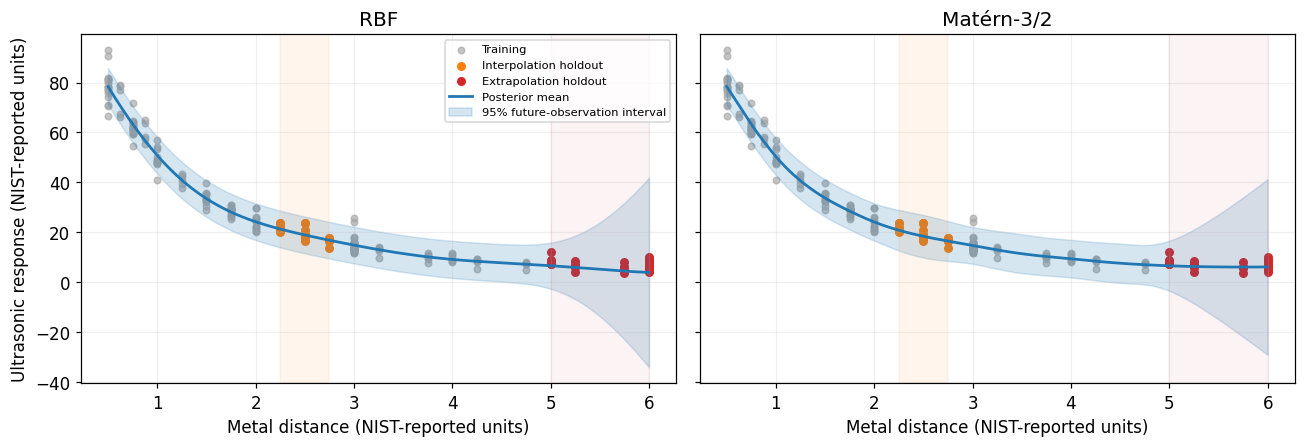

,Model,Split,RMSE,Mean NLPD,95% coverage,Mean 95% interval width
0,RBF,Interpolation,1.851,2.363,1.0,14.707
1,RBF,Extrapolation,2.629,3.393,1.0,51.773
2,Matérn-3/2,Interpolation,1.986,2.460,1.0,16.451
3,Matérn-3/2,Extrapolation,1.893,3.394,1.0,50.471


In [7]:
def gp_predict(fit, prediction_distance):
    kernel = fit["kernel"]
    amplitude, length_scale, noise_sd = fit["parameters"]
    covariance = kernel(training_distance, training_distance, amplitude, length_scale)
    covariance.flat[:: covariance.shape[0] + 1] += noise_sd**2 + 1e-8
    factor, lower = cho_factor(covariance, lower=True, check_finite=False)
    cross_covariance = kernel(training_distance, prediction_distance, amplitude, length_scale)
    alpha = cho_solve((factor, lower), training_response, check_finite=False)
    standardized_mean = cross_covariance.T @ alpha
    solved_cross = cho_solve((factor, lower), cross_covariance, check_finite=False)
    standardized_latent_covariance = (
        kernel(prediction_distance, prediction_distance, amplitude, length_scale)
        - cross_covariance.T @ solved_cross
    )
    standardized_latent_covariance = 0.5 * (
        standardized_latent_covariance + standardized_latent_covariance.T
    )
    standardized_observation_covariance = standardized_latent_covariance.copy()
    standardized_observation_covariance.flat[
        :: standardized_observation_covariance.shape[0] + 1
    ] += noise_sd**2
    mean = training_mean + training_sd * standardized_mean
    latent_covariance = training_sd**2 * standardized_latent_covariance
    observation_covariance = training_sd**2 * standardized_observation_covariance
    return mean, latent_covariance, observation_covariance


def predictive_metrics(mask, mean, observation_variance):
    truth = response[mask]
    rmse = np.sqrt(np.mean((truth - mean) ** 2))
    mean_nlpd = np.mean(
        0.5 * np.log(2.0 * np.pi * observation_variance)
        + 0.5 * (truth - mean) ** 2 / observation_variance
    )
    predictive_sd = np.sqrt(observation_variance)
    coverage = np.mean(
        (truth >= mean - 1.96 * predictive_sd)
        & (truth <= mean + 1.96 * predictive_sd)
    )
    mean_interval_width = np.mean(2.0 * 1.96 * predictive_sd)
    return rmse, mean_nlpd, coverage, mean_interval_width


grid = np.linspace(distance.min(), distance.max(), 500)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True, sharey=True)
metric_rows = []
held_out = {"Interpolation": interpolation_mask, "Extrapolation": extrapolation_mask}
predictions = {}

for axis, (model_name, fit) in zip(axes, fits.items()):
    grid_mean, _, grid_observation_covariance = gp_predict(fit, grid)
    grid_observation_variance = np.diag(grid_observation_covariance)
    grid_sd = np.sqrt(grid_observation_variance)
    axis.scatter(distance[training_mask], response[training_mask], s=18, color="0.65",
                 alpha=0.65, label="Training")
    axis.scatter(distance[interpolation_mask], response[interpolation_mask], s=24,
                 color="tab:orange", label="Interpolation holdout")
    axis.scatter(distance[extrapolation_mask], response[extrapolation_mask], s=24,
                 color="tab:red", label="Extrapolation holdout")
    axis.plot(grid, grid_mean, color="tab:blue", lw=1.8, label="Posterior mean")
    axis.fill_between(grid, grid_mean - 1.96 * grid_sd, grid_mean + 1.96 * grid_sd,
                      color="tab:blue", alpha=0.18, label="95% future-observation interval")
    axis.axvspan(2.25, 2.75, color="tab:orange", alpha=0.07)
    axis.axvspan(5.0, 6.0, color="tab:red", alpha=0.05)
    axis.set(title=model_name, xlabel="Metal distance (NIST-reported units)")
    axis.grid(alpha=0.2)

    predictions[model_name] = {}
    for split_name, mask in held_out.items():
        mean, latent_covariance, observation_covariance = gp_predict(
            fit, distance[mask]
        )
        latent_variance = np.diag(latent_covariance)
        observation_variance = np.diag(observation_covariance)
        predictions[model_name][split_name] = {
            "mean": mean,
            "latent_covariance": latent_covariance,
            "observation_covariance": observation_covariance,
            "latent_variance": latent_variance,
            "observation_variance": observation_variance,
        }
        rmse, mean_nlpd, coverage, mean_interval_width = predictive_metrics(
            mask, mean, observation_variance
        )
        metric_rows.append({
            "Model": model_name,
            "Split": split_name,
            "RMSE": rmse,
            "Mean NLPD": mean_nlpd,
            "95% coverage": coverage,
            "Mean 95% interval width": mean_interval_width,
        })

axes[0].set_ylabel("Ultrasonic response (NIST-reported units)")
axes[0].legend(loc="upper right", fontsize=7.5)
figure.tight_layout()
plt.show()

metric_table = pd.DataFrame(metric_rows)
display(metric_table.round({
    "RMSE": 3,
    "Mean NLPD": 3,
    "95% coverage": 3,
    "Mean 95% interval width": 3,
}))


### (c) Make a preliminary interpolation comparison (20 points)

Using the **interpolation** rows of the metrics table, which model has the better preliminary predictive performance? Support your answer with the RMSE, mean NLPD, and mean 95% interval width. Briefly explain what each quantity contributes to the comparison. Treat this as a preliminary judgment; part (d) will check calibration more directly.


*Your answer:*


The **RBF model has better preliminary predictive performance** on the interpolation holdout:

| Model | RMSE | Mean NLPD | Mean 95% interval width |
|---|---:|---:|---:|
| RBF | 1.851 | 2.363 | 14.707 |
| Matérn-3/2 | 1.986 | 2.460 | 16.451 |

- **RMSE:** RBF has the lower RMSE ($1.851$ versus $1.986$), indicating smaller typical errors in its posterior-mean predictions. RMSE evaluates point-prediction accuracy but does not account for predictive uncertainty.

- **Mean NLPD:** RBF also has the lower mean NLPD ($2.363$ versus $2.460$). This evaluates the predictive distributions, rewarding accurate means and appropriate variances while penalizing both overconfident errors and unnecessarily diffuse predictions.

- **Mean 95% interval width:** RBF has narrower intervals on average ($14.707$ versus $16.451$ response units), indicating sharper predictions. Narrower intervals are desirable only when they remain adequately calibrated.

Both models have empirical interpolation coverage of $1.000$: all 26 held-out observations fall within their pointwise 95% predictive intervals. Thus, RBF provides slightly more accurate point predictions, a better predictive-density score, and sharper intervals on this holdout.

This conclusion is preliminary. Coverage of 100% does not establish correct calibration and may indicate overly wide intervals. Part (d) will examine calibration more directly.

### Diagnostics: how they work

**Credit:** Course adaptation of the standardized-error diagnostics in Lecture 22 and Leonardo S. Bastos and Anthony O'Hagan, [“Diagnostics for Gaussian Process Emulators,”](https://doi.org/10.1198/TECH.2009.08019) *Technometrics* 51 (2009), 425–438. The idea used here is that diagnostics for several validation values should account for their predictive correlation. We use the Gaussian reference distribution conditional on the fitted hyperparameters.

For the $n_v=26$ interpolation observations, the **joint posterior predictive distribution for future noisy observations** is

$$
\mathbf{Y}^v\mid\mathcal{D}
\sim
\mathcal{N}\!\left(\mathbf{m}^v,\boldsymbol{\Sigma}^v\right).
$$

The full matrix $\boldsymbol{\Sigma}^v$ includes observation noise and correlations among the validation predictions.

Start with the marginal standardized prediction errors

$$
e_i
=
\frac{y_i^v-m_i^v}{\sqrt{\Sigma^v_{ii}}}.
$$

If the predictive model is appropriate, each $e_i$ is marginally standard normal. We therefore look for a mean near $0$, a sample standard deviation near $1$, no visible pattern in the error plot, and roughly 95% of the values between $-1.96$ and $1.96$. These errors are generally correlated, so their ordinary sum of squares does not provide the correct joint check.

To account for the correlation, factor the predictive covariance as $\boldsymbol{\Sigma}^v=\mathbf{L}\mathbf{L}^\top$ and form the whitened errors

$$
\mathbf{z}
=
\mathbf{L}^{-1}(\mathbf{y}^v-\mathbf{m}^v).
$$

Under the fitted Gaussian model, the components of $\mathbf{z}$ are independent standard-normal variables. Their Q–Q plot should therefore be close to the reference line. Their squared length is the Mahalanobis diagnostic

$$
D_M^2
=
(\mathbf{y}^v-\mathbf{m}^v)^\top
(\boldsymbol{\Sigma}^v)^{-1}
(\mathbf{y}^v-\mathbf{m}^v)
=\mathbf{z}^\top\mathbf{z}.
$$

Conditional on the fitted model, $D_M^2$ has a $\chi^2_{n_v}$ reference distribution. A value above the central reference interval means that the joint errors are larger than the model predicts. A value below the interval means that they are smaller than predicted, which may indicate intervals that are too wide or an unusually easy validation set.

Run the supplied cell. In the left panels, the horizontal lines are $0$ and $\pm1.96$. In the right panels, the Q–Q plots use the Cholesky-whitened errors with the fixed validation-observation ordering.


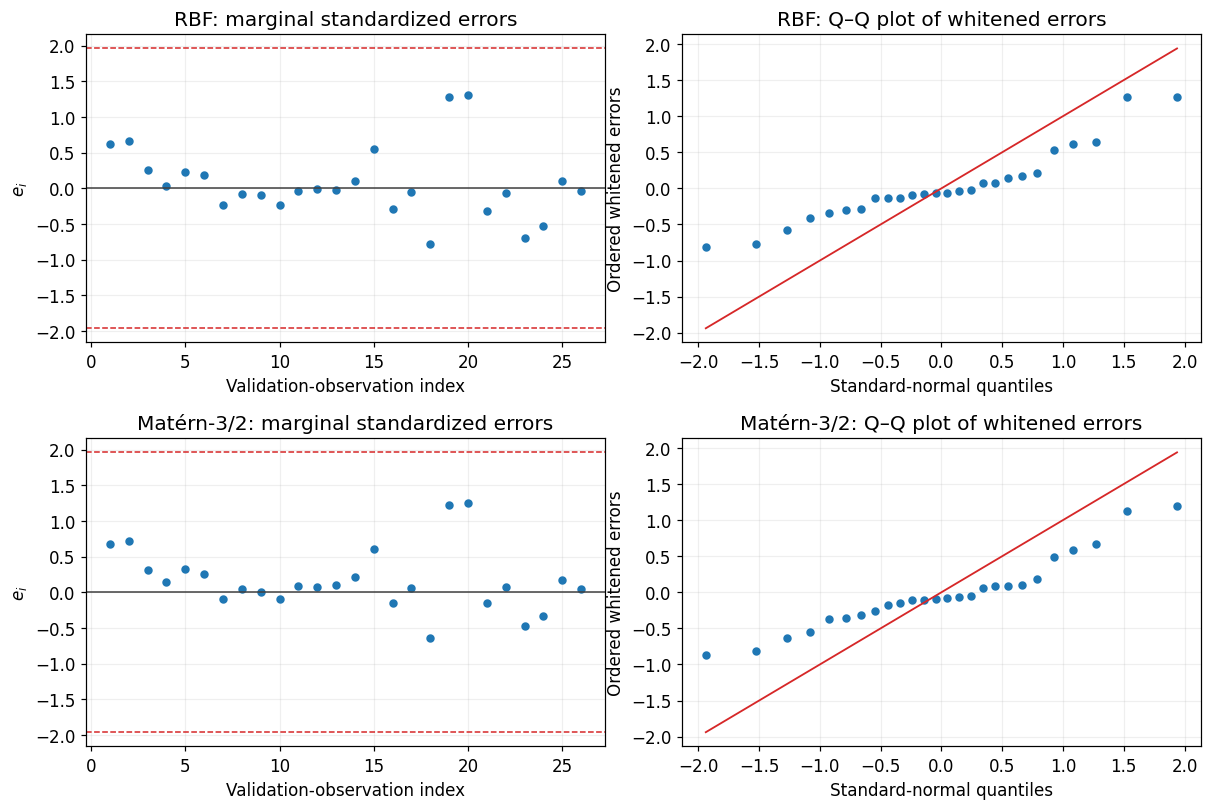

Marginal diagnostics


,Model,Mean of e_i,Sample SD of e_i,Fraction with |e_i| <= 1.96
0,RBF,0.071,0.498,1.0
1,Matérn-3/2,0.171,0.440,1.0


Correlation-aware joint diagnostics


,Model,n_v,Mahalanobis D^2,D^2 / n_v,Chi-square reference percentile,Central 95% lower,Central 95% upper
0,RBF,26,6.496,0.250,0.000036,13.844,41.923
1,Matérn-3/2,26,6.443,0.248,0.000033,13.844,41.923


In [8]:
validation_mask = interpolation_mask
validation_size = int(validation_mask.sum())
chi_square_interval = chi2.ppf([0.025, 0.975], df=validation_size)
marginal_rows = []
joint_rows = []
diagnostic_values = {}

figure, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for row_index, (model_name, fit) in enumerate(fits.items()):
    prediction = predictions[model_name]["Interpolation"]
    residual = response[validation_mask] - prediction["mean"]
    predictive_covariance = prediction["observation_covariance"]
    marginal_sd = np.sqrt(np.diag(predictive_covariance))
    standardized_error = residual / marginal_sd

    cholesky_factor = np.linalg.cholesky(predictive_covariance)
    whitened_error = np.linalg.solve(cholesky_factor, residual)
    mahalanobis_squared = float(whitened_error @ whitened_error)
    reference_percentile = float(
        chi2.cdf(mahalanobis_squared, df=validation_size)
    )
    diagnostic_values[model_name] = {
        "standardized_error": standardized_error,
        "whitened_error": whitened_error,
        "mahalanobis_squared": mahalanobis_squared,
    }

    marginal_rows.append({
        "Model": model_name,
        "Mean of e_i": standardized_error.mean(),
        "Sample SD of e_i": standardized_error.std(ddof=1),
        "Fraction with |e_i| <= 1.96": np.mean(np.abs(standardized_error) <= 1.96),
    })
    joint_rows.append({
        "Model": model_name,
        "n_v": validation_size,
        "Mahalanobis D^2": mahalanobis_squared,
        "D^2 / n_v": mahalanobis_squared / validation_size,
        "Chi-square reference percentile": reference_percentile,
        "Central 95% lower": chi_square_interval[0],
        "Central 95% upper": chi_square_interval[1],
    })

    error_axis = axes[row_index, 0]
    error_axis.plot(
        np.arange(1, validation_size + 1), standardized_error, "o", ms=4.5
    )
    error_axis.axhline(0.0, color="0.25", lw=1.0)
    error_axis.axhline(1.96, color="tab:red", ls="--", lw=1.0)
    error_axis.axhline(-1.96, color="tab:red", ls="--", lw=1.0)
    error_axis.set(
        title=f"{model_name}: marginal standardized errors",
        xlabel="Validation-observation index",
        ylabel="$e_i$",
    )
    error_axis.grid(alpha=0.2)

    theoretical_quantiles, ordered_errors = probplot(
        whitened_error, dist="norm", fit=False
    )
    qq_axis = axes[row_index, 1]
    qq_axis.plot(theoretical_quantiles, ordered_errors, "o", ms=4.5)
    lower = min(np.min(theoretical_quantiles), np.min(ordered_errors))
    upper = max(np.max(theoretical_quantiles), np.max(ordered_errors))
    qq_axis.plot([lower, upper], [lower, upper], color="tab:red", lw=1.2)
    qq_axis.set(
        title=f"{model_name}: Q–Q plot of whitened errors",
        xlabel="Standard-normal quantiles",
        ylabel="Ordered whitened errors",
    )
    qq_axis.grid(alpha=0.2)

figure.tight_layout()
plt.show()

marginal_diagnostic_table = pd.DataFrame(marginal_rows)
joint_diagnostic_table = pd.DataFrame(joint_rows)
print("Marginal diagnostics")
display(marginal_diagnostic_table.round(3))
print("Correlation-aware joint diagnostics")
display(joint_diagnostic_table.round({
    "Mahalanobis D^2": 3,
    "D^2 / n_v": 3,
    "Chi-square reference percentile": 6,
    "Central 95% lower": 3,
    "Central 95% upper": 3,
}))


### (d) Use the diagnostics (35 points)

You do not need to derive any of the diagnostic formulas. Use the two diagnostic tables and the plots to assess the RBF and Matérn-$3/2$ predictive distributions on the interpolation holdout.

For each model:

1. Report the mean and sample standard deviation of the marginal standardized errors and the fraction inside $[-1.96,1.96]$.
2. Describe what the standardized-error and whitened-error Q–Q plots show.
3. Compare the Mahalanobis distance with the central 95% $\chi^2_{26}$ reference interval.

Conclude whether the predictive uncertainty appears too narrow, about right, or too wide. Explain why 100% empirical coverage does not by itself demonstrate good calibration. State whether these diagnostics change your preliminary model preference from part (c), and give one plausible explanation other than excessive predictive variance for an unusually small Mahalanobis distance.


*Your answer:*

The interpolation diagnostics are summarized below.

| Model | Mean of $e_i$ | Sample SD of $e_i$ | Fraction within $[-1.96,1.96]$ | Mahalanobis $D_M^2$ | $D_M^2/26$ |
|---|---:|---:|---:|---:|---:|
| RBF | 0.071 | 0.498 | 1.000 | 6.496 | 0.250 |
| Matérn-3/2 | 0.171 | 0.440 | 1.000 | 6.443 | 0.248 |

For both models, the central 95% reference interval of the $\chi^2_{26}$ distribution is

$$
[13.844,\;41.923].
$$

**RBF model**

The marginal standardized errors have mean $0.071$, sample standard deviation $0.498$, and all lie within $[-1.96,1.96]$. Their mean is close to zero, suggesting little average prediction bias on this holdout. However, their spread is substantially smaller than the marginal standard-normal reference scale.

The standardized-error plot shows errors concentrated around zero, with a few larger positive errors and no strong overall trend. The whitened-error Q–Q plot is compressed relative to the standard-normal reference line: the lower-tail points lie above the line and the upper-tail points lie below it. This indicates less variation than the predictive distribution anticipates.

The joint diagnostic is

$$
D_M^2=6.496<13.844,
$$

with chi-square reference percentile $0.000036$. Thus, even after accounting for predictive correlations, the observed errors are unusually small relative to the predicted uncertainty.

**Matérn-3/2 model**

The marginal standardized errors have mean $0.171$, sample standard deviation $0.440$, and all lie within $[-1.96,1.96]$. The positive mean suggests a small average tendency to underpredict, but the main feature is again the small error spread.

The standardized-error plot shows errors clustered near zero, with some runs of similarly signed errors and a few larger positive values. Its whitened-error Q–Q plot also shows compressed tails relative to the standard-normal reference line.

The joint diagnostic is

$$
D_M^2=6.443<13.844,
$$

with chi-square reference percentile $0.000033$. The joint errors are therefore also much smaller than this model predicts.

**Calibration and model preference**

For both models, the diagnostics suggest that predictive uncertainty is **too wide on this interpolation holdout**, rather than about right or too narrow. The marginal errors have small spreads, the whitened Q–Q plots show compressed tails, and both Mahalanobis statistics fall below the central reference interval. The marginal sample standard deviations alone are not decisive because the errors are correlated; the correlation-aware joint checks strengthen this conclusion.

Empirical coverage of 100% does not by itself demonstrate good calibration. Very wide intervals can contain every observation while overstating uncertainty. Calibration concerns agreement between predicted uncertainty and observed errors, rather than maximizing coverage.

These diagnostics do not reverse the preliminary preference for **RBF** from part (c): it has lower interpolation RMSE and mean NLPD, and narrower intervals. However, neither model appears well calibrated on this holdout, so the preference remains qualified.

One plausible explanation other than excessive predictive variance is that this particular validation set is unusually easy. It contains only three distinct distance levels, all inside the training range, and the realized responses may happen to lie especially close to the predicted means. The chi-square comparison is also conditional on the fitted hyperparameters, rather than accounting for uncertainty in their estimation.